# Before-and-after experiment Pipeline
Run cells in order with Shift + Enter using the project .venv kernel.

**Detect → evaluate baseline → train → evaluate new model → detect → compare.**

This notebook calls YOLO directly so it can capture the exact newly trained weights. Settings here are independent of src/train.py. Both evaluations use validation data; reserve the test split for your final selected model.

Default: compare your existing holds_detector model with a model further trained from those weights. To compare it with a fresh training run, set TRAIN_START to models/yolo26n.pt instead.

The original pretrained model has different classes. For a before/after experiment starting with yolo26n.pt itself, set both weight paths to that file and CLASS_AGNOSTIC=True. That compares **localization of any annotated hold/volume**, ignoring type; it is not a hold-classification score. Unrelated pretrained detections count as false positives. Keep this setting identical before and after.


In [17]:
from pathlib import Path
from datetime import datetime
import json
import yaml
import torch
from ultralytics import YOLO
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/detect.py").is_file() and (p / "models").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Launch the notebook from the ClimbingAI project.")
BASELINE_WEIGHTS = ROOT / "models/holds_detector/weights/best.pt"
TRAIN_START = BASELINE_WEIGHTS  # Or ROOT / "models/yolo26n.pt" for fresh fine-tuning.
CLASS_AGNOSTIC = False
PHOTO = ROOT / "data/raw/1.jpg"
DATA = ROOT / "data/climbing-holds-v14/data.yaml"
EPOCHS = 30
IMGSZ = 640
BATCH = 8
DEVICE = "mps" if torch.backends.mps.is_available() else (0 if torch.cuda.is_available() else "cpu")
CONF = 0.25  # Display threshold; evaluation uses its own fixed threshold below.
RUN_TRAINING = False  # Set True when ready to run the training cell.
for p in [BASELINE_WEIGHTS, TRAIN_START, PHOTO, DATA]:
    if not p.is_file():
        raise FileNotFoundError(p)
EXPERIMENT = ROOT / "models" / ("comparison_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
EXPERIMENT.mkdir(parents=True, exist_ok=False)
config = dict(baseline=str(BASELINE_WEIGHTS), train_start=str(TRAIN_START),
              photo=str(PHOTO), data=str(DATA), epochs=EPOCHS, imgsz=IMGSZ,
              batch=BATCH, device=DEVICE, single_cls=CLASS_AGNOSTIC, split="val", seed=0)
(EXPERIMENT / "experiment.json").write_text(json.dumps(config, indent=2))
print("Results folder:", EXPERIMENT)
print("Device:", DEVICE)


Results folder: /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252
Device: mps


In [18]:
def detect_and_show(weights, name):
    model = YOLO(str(weights))
    predictions = model.predict(source=str(PHOTO), conf=CONF, imgsz=IMGSZ, device=DEVICE)
    output = EXPERIMENT / f"{name}.jpg"
    predictions[0].save(filename=str(output))
    display(Image(filename=str(output), width=900))
    print("Saved:", output)


def evaluate(weights, name):
    model = YOLO(str(weights))
    names = yaml.safe_load(DATA.read_text())["names"]
    expected = dict(enumerate(names)) if isinstance(names, list) else names
    if not CLASS_AGNOSTIC and model.names != expected:
        raise ValueError("Model and dataset classes differ. Choose hold-trained weights, "
                         "or use CLASS_AGNOSTIC=True for a localization-only experiment.")
    metrics = model.val(data=str(DATA), split="val", imgsz=IMGSZ, batch=BATCH,
                        device=DEVICE, single_cls=CLASS_AGNOSTIC, conf=0.001,
                        iou=0.7, max_det=300, seed=0, augment=False,
                        project=str(EXPERIMENT), name=name, exist_ok=False, plots=True)
    scores = {"precision": float(metrics.box.mp), "recall": float(metrics.box.mr),
              "mAP50": float(metrics.box.map50), "mAP50-95": float(metrics.box.map)}
    (Path(metrics.save_dir) / "metrics.json").write_text(json.dumps(scores, indent=2))
    print(json.dumps(scores, indent=2))
    return scores


## 1. Detect with the baseline model
Inspect the boxes and labels before training.



image 1/1 /Users/walter/Desktop/Projects/ClimbingAI/data/raw/1.jpg: 416x640 5 0s, 4.7ms
Speed: 1.2ms preprocess, 4.7ms inference, 13.4ms postprocess per image at shape (1, 3, 416, 640)


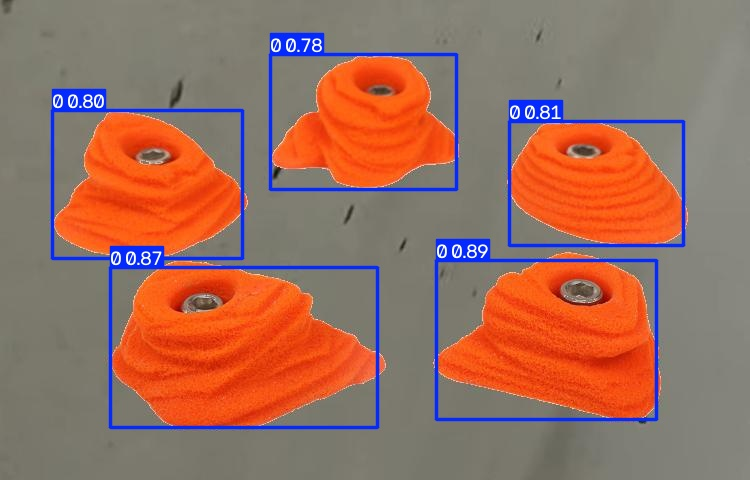

Saved: /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252/before.jpg


In [19]:
detect_and_show(BASELINE_WEIGHTS, "before")


## 2. Evaluate the baseline
These validation metrics are your comparison point.


In [20]:
before_scores = evaluate(BASELINE_WEIGHTS, "before_validation")


Ultralytics 8.4.192 🚀 Python-3.15.0 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 396.4±62.2 MB/s, size: 97.4 KB)
val: Scanning /Users/walter/Desktop/Projects/ClimbingAI/data/climbing-holds-v14/valid/labels.cache... 277 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 277/277 40.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 9.1it/s 3.8s0.1s
                   all        277      11335      0.694      0.615      0.646      0.426
                     0        219      10421      0.791      0.668      0.687      0.427
                     1        212        914      0.598      0.561      0.606      0.425
Speed: 0.2ms preprocess, 2.1ms inference, 0.0ms loss, 4.7ms postprocess per image
Results saved to /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252/before_val

## 3. Train
Set RUN_TRAINING=True in the configuration cell before starting the experiment. This starts a new fine-tuning run, not an optimizer-state resume. Existing model files are preserved. Early stopping uses patience=10.

If training is skipped, the remaining cells will also skip until a new model exists in this notebook session. The best checkpoint may occur before the last epoch.


In [21]:
after_weights = None
RUN_TRAINING = True  # Set True when ready to run the training cell.
if RUN_TRAINING:
    if "before_scores" not in globals():
        raise RuntimeError("Run the baseline evaluation first.")
    training_model = YOLO(str(TRAIN_START))
    training_model.train(data=str(DATA), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                         device=DEVICE, project=str(EXPERIMENT), name="training",
                         exist_ok=False, patience=10, seed=0)
    after_weights = Path(training_model.trainer.save_dir) / "weights/best.pt"
    if not after_weights.is_file():
        raise FileNotFoundError(after_weights)
    print("New best weights:", after_weights)
    (EXPERIMENT / "selected_weights.txt").write_text(str(after_weights))
else:
    print("Training skipped. Set RUN_TRAINING=True to enable it.")


New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.192 🚀 Python-3.15.0 torch-2.15.0 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/walter/Desktop/Projects/ClimbingAI/data/climbing-holds-v14/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

/Users/walter/Desktop/Projects/ClimbingAI/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      4.31G      1.581      1.038   0.004366        248        640: 100% ━━━━━━━━━━━━ 484/484 1.7it/s 4:530.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.7it/s 10.6s0.4s
                   all        277      11335      0.756      0.664      0.716      0.502

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/30      3.28G      1.846      1.033    0.00406        337        640: 0% ──────────── 0/484  0.8s

/Users/walter/Desktop/Projects/ClimbingAI/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/30      4.27G      1.573     0.9663   0.004203        354        640: 100% ━━━━━━━━━━━━ 484/484 1.7it/s 4:420.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.7it/s 10.7s0.5s
                   all        277      11335      0.765       0.67      0.722      0.501

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30      3.26G      1.622      1.165   0.004642        502        640: 0% ──────────── 0/484  1.1s

/Users/walter/Desktop/Projects/ClimbingAI/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (18 outputs left out)

      12/30      4.28G      1.429     0.7684   0.003587        313        640: 100% ━━━━━━━━━━━━ 484/484 1.3it/s 6:170.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.5it/s 11.9s0.6s
                   all        277      11335      0.827      0.744      0.787      0.583

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      13/30      3.28G       1.67     0.8644   0.003491        709        640: 0% ──────────── 0/484  1.1s

/Users/walter/Desktop/Projects/ClimbingAI/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      13/30      4.32G      1.405     0.7399   0.003468        444        640: 10% ━─────────── 49/484 1.7it/s 38.2s<4:16


KeyboardInterrupt: 

## 4. Evaluate the newly trained model
Use the same validation split and evaluation settings as the baseline.


In [24]:
# Recover the best saved checkpoint from the interrupted training run.
after_weights = Path(training_model.trainer.save_dir) / "weights" / "best.pt"

if not after_weights.is_file():
    raise FileNotFoundError(
        "No checkpoint was saved yet. At least one epoch needs to finish."
    )

print("Using checkpoint:", after_weights)

Using checkpoint: /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252/training/weights/best.pt


In [25]:
after_scores = None
if after_weights is not None:
    after_scores = evaluate(after_weights, "after_validation")
else:
    print("No new model yet; evaluation skipped.")


Ultralytics 8.4.192 🚀 Python-3.15.0 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 378.9±170.9 MB/s, size: 83.4 KB)
val: Scanning /Users/walter/Desktop/Projects/ClimbingAI/data/climbing-holds-v14/valid/labels.cache... 277 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 277/277 228.0Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.0it/s 5.9s0.3s
                   all        277      11335      0.814      0.744      0.783      0.585
                     0        219      10421      0.832      0.735      0.745      0.518
                     1        212        914      0.797      0.753       0.82      0.652
Speed: 0.2ms preprocess, 7.4ms inference, 0.0ms loss, 4.6ms postprocess per image
Results saved to /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252/after_va

## 5. Detect with the newly trained model
Use the same photo and display confidence threshold as before training.



image 1/1 /Users/walter/Desktop/Projects/ClimbingAI/data/raw/1.jpg: 416x640 5 0s, 7.4ms
Speed: 5.0ms preprocess, 7.4ms inference, 22.2ms postprocess per image at shape (1, 3, 416, 640)


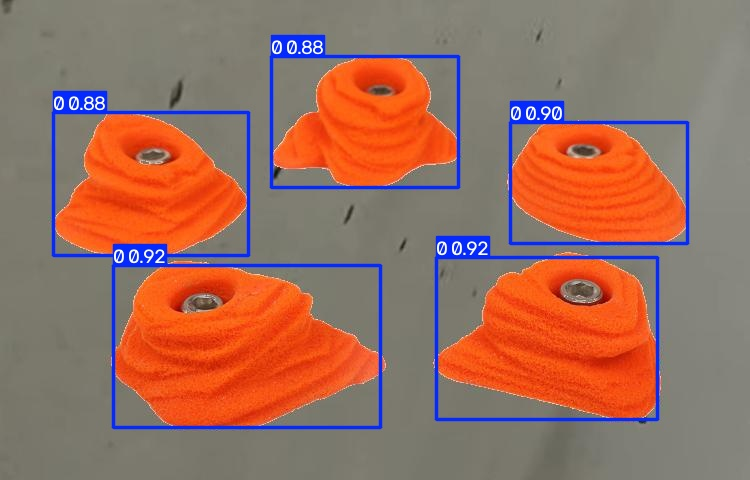

Saved: /Users/walter/Desktop/Projects/ClimbingAI/models/comparison_20261104_200339_350252/after.jpg


In [26]:
if after_weights is not None:
    detect_and_show(after_weights, "after")
else:
    print("No new model yet; detection skipped.")


## 6. Compare and record
Positive changes indicate higher scores, but inspect the images too. More training does not guarantee improvement.


In [27]:
if after_scores is not None:
    print(f"{'Metric':<14} {'Before':>9} {'After':>9} {'Change':>9}")
    for key, before in before_scores.items():
        after = after_scores[key]
        print(f"{key:<14} {before:>9.4f} {after:>9.4f} {after-before:>+9.4f}")
    (EXPERIMENT / "comparison.json").write_text(json.dumps(
        {"before": before_scores, "after": after_scores, "config": config,
         "after_weights": str(after_weights)}, indent=2))
else:
    print("Complete training and both evaluations to compare results.")


Metric            Before     After    Change
precision         0.6944    0.8145   +0.1200
recall            0.6146    0.7437   +0.1291
mAP50             0.6464    0.7825   +0.1361
mAP50-95          0.4259    0.5850   +0.1591


### Experiment notes
- Missed holds before / after:
- False detections before / after:
- Which model would you keep, and why?
- Next change to try:

Results are stored in the printed comparison folder under models/ (already ignored by Git). After choosing a final model, assess it on the reserved test split. Clear notebook outputs before committing to avoid adding large images and logs.
